In [2]:
# 1. Kết nối Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Lấy dữ liệu 05_Data từ file test.zip trên Drive
!unzip -qo "/content/drive/MyDrive/test.zip" -d /content/
!cp -r /content/test/05_Data /content/
!rm -rf /content/test

# 3. Cài thư viện tách từ tiếng Việt & tải model VnCoreNLP thật
!pip install -q underthesea py_vncorenlp
import os, py_vncorenlp
os.makedirs('/content/VnCoreNLP', exist_ok=True)
py_vncorenlp.download_model(save_dir='/content/VnCoreNLP')

Mounted at /content/drive
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Cảnh báo: Không nạp được VnCoreNLP (No vn/pipeline/VnCoreNLP constructor matching your arguments, requested: ('wseg',), available: ['()V', '([Ljava/lang/String;)V']), sẽ fallback về text gốc.

========== BASELINE NO_SEGMENTATION ==========
              precision    recall  f1-score   support

           0       0.87      0.89      0.88      1409
           1       0.29      0.50      0.37       167
           2       0.95      0.86      0.91      1590

    accuracy                           0.86      3166
   macro avg       0.71      0.75      0.72      3166
weighted avg       0.88      0.86      0.87      3166



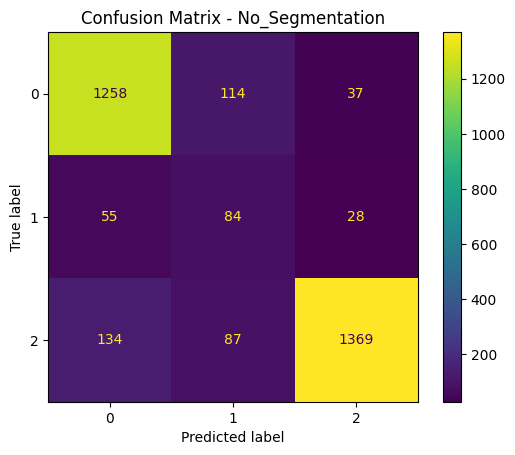


========== BASELINE UNDERTHESEA ==========
              precision    recall  f1-score   support

           0       0.88      0.89      0.89      1409
           1       0.28      0.50      0.36       167
           2       0.95      0.86      0.90      1590

    accuracy                           0.86      3166
   macro avg       0.70      0.75      0.72      3166
weighted avg       0.88      0.86      0.87      3166



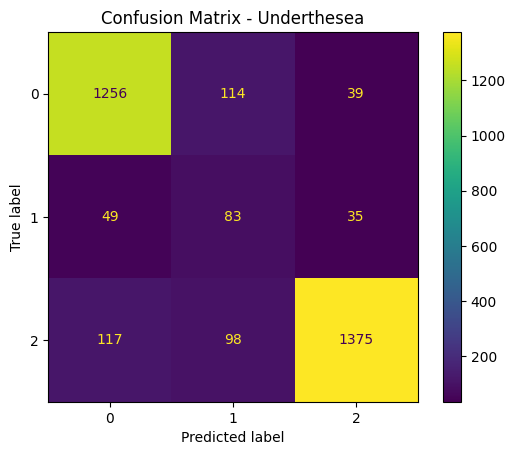


========== BASELINE VNCORENLP ==========
              precision    recall  f1-score   support

           0       0.87      0.89      0.88      1409
           1       0.29      0.50      0.37       167
           2       0.95      0.86      0.91      1590

    accuracy                           0.86      3166
   macro avg       0.71      0.75      0.72      3166
weighted avg       0.88      0.86      0.87      3166



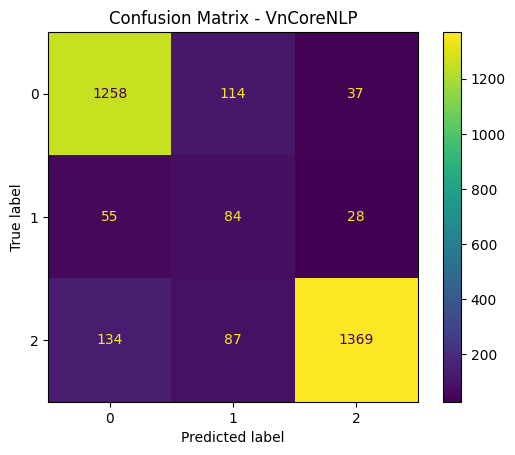

In [3]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from underthesea import word_tokenize
import py_vncorenlp

# Hàm chuẩn hóa văn bản đồng bộ với toàn đồ án
def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"\b(gv|thầy|cô)\b", "giảng viên", text)
    text = re.sub(r"\b(sv)\b", "sinh viên", text)
    text = re.sub(r"\b(slide|slđ)\b", "bài giảng", text)
    text = re.sub(r"\b(đc)\b", "được", text)
    text = re.sub(r"\b(khg|ko|kh|k)\b", "không", text)
    text = re.sub(r"\b(ok|ổn)\b", "tạm ổn", text)
    text = re.sub(r"[^\w\s,.+\-]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# 1. TẢI DỮ LIỆU
train_df = pd.read_csv("/content/05_Data/processed/train_cleaned.csv").dropna()
test_df  = pd.read_csv("/content/05_Data/raw/test.csv").dropna()

# 2. ĐỊNH NGHĨA 3 PHƯƠNG PHÁP TÁCH TỪ
def no_segmentation(text):
    return text

def underthesea_segmentation(text):
    return word_tokenize(text, format="text")

# Khởi tạo VnCoreNLP (cần tải model về thư mục ./VnCoreNLP nếu dùng)
try:
    rdrsegmenter = py_vncorenlp.VnCoreNLP(annotators="wseg", save_dir='/content/VnCoreNLP')
except Exception as e:
    print(f"Cảnh báo: Không nạp được VnCoreNLP ({e}), sẽ fallback về text gốc.")
    rdrsegmenter = None

def vncorenlp_segmentation(text):
    if rdrsegmenter is None:
        return text
    sentences = rdrsegmenter.annotate_text(text)
    words = [word['form'] for sentence in sentences.values() for word in sentence]
    return " ".join(words)

# 3. HÀM ĐÁNH GIÁ VÀ VẼ BIỂU ĐỒ (Đồng bộ tách từ trên cả Train và Test)
os.makedirs("/content/2_Result", exist_ok=True)

def evaluate_method(segmentation_func, method_name, model):
    print(f"\n{'='*10} BASELINE {method_name.upper()} {'='*10}")

    # Áp dụng cùng 1 hàm tách từ cho cả Train và Test
    X_train_seg = train_df['tokenized'].astype(str).apply(segmentation_func)
    X_test_seg  = test_df['comment'].astype(str).apply(clean_text).apply(segmentation_func)

    # Vector hóa (chỉ fit trên Train, transform trên Test)
    tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=5000)
    X_train_vec = tfidf.fit_transform(X_train_seg)
    X_test_vec  = tfidf.transform(X_test_seg)

    # Huấn luyện
    model.fit(X_train_vec, train_df['label'])

    # Dự đoán
    y_pred = model.predict(X_test_vec)

    # In báo cáo
    print(classification_report(test_df['label'], y_pred))

    # Vẽ và lưu Confusion Matrix
    ConfusionMatrixDisplay.from_predictions(test_df['label'], y_pred)
    plt.title(f"Confusion Matrix - {method_name}")
    plt.savefig(f'/content/2_Result/Confusion_Matrix_{method_name}.png')
    plt.show()

# 4. CHẠY THỬ NGHIỆM
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

evaluate_method(no_segmentation, "No_Segmentation", model)
evaluate_method(underthesea_segmentation, "Underthesea", model)
evaluate_method(vncorenlp_segmentation, "VnCoreNLP", model)


In [5]:
import os
os.environ['HF_HUB_DISABLE_SYMLINKS'] = '1'
from transformers import AutoTokenizer

# Khởi tạo tokenizer
tokenizer = AutoTokenizer.from_pretrained("vinai/phobert-base")
import pandas as pd
import torch
from torch.utils.data import Dataset

df = pd.read_csv('/content/05_Data/processed/train_cleaned.csv')

# 2. Định nghĩa một Dataset class
class TextDataset(Dataset):
    def __init__(self, texts, tokenizer, max_length=256):
        self.texts = texts
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        inputs = self.tokenizer(
            text,
            padding='max_length',
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )
        return {
            'input_ids': inputs['input_ids'].squeeze(0),
            'attention_mask': inputs['attention_mask'].squeeze(0)
        }

dataset = TextDataset(df['tokenized'].values, tokenizer)

sample = dataset[0]
print(sample['input_ids'])

tensor([    0, 48090,  4368,  1893,   545,   312,     2,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1, 

In [6]:
!zip -r /content/seg_results.zip /content/2_Result/

  adding: content/2_Result/ (stored 0%)
  adding: content/2_Result/Confusion_Matrix_No_Segmentation.png (deflated 12%)
  adding: content/2_Result/Confusion_Matrix_Underthesea.png (deflated 12%)
  adding: content/2_Result/Confusion_Matrix_VnCoreNLP.png (deflated 12%)
